In [1]:
import sibil
base_path = "/global/cfs/projectdirs/m4491/btaczak/SIBIL-runs/DIIID_LSN_noC_demonstration/2_iteration"
softmax_scales = {
    "ni": (1e16, 1e15),
    "ne": (1e16, 1e15),
    "Ti": (5e-1, 1e-4),
    "Te": (5e-1, 1e-4),
}
config = {
    'gfile_loc': f'{base_path}/../g184016.03200',
    'geofile_loc': f'{base_path}/../HvsD_Dmesh_noC_v1.v001.geo',
    'bgrid_loc': f'{base_path}/Shelf_new_grid2_sinks2_gradfix/d3d_shelf_184016.03200_nc3.grd.nc',
    'b2fstate_loc': f'{base_path}/b2fstate',
    'b2fplasmf_loc': f'{base_path}/b2fplasmf',
    'b2fgmtry_loc': f'{base_path}/b2fgmtry',
    'softmax_scales': softmax_scales,
}
mapper = sibil.SIBIL_Midplane_Mapper(config)

SIBIL Succsessfully Imported
Loading the config file
Initializing the mapping objects
Performing mapping calculations
Setting all poloidal profiles to midplane profile
Updating the bout++ grid file
---------------------------------------
SOLPS-ITER |          Min |          Max
---------------------------------------
ni         |   4.9261e+18 |   3.2709e+20
ne         |   4.9261e+18 |   3.2709e+20
Ti         |       0.9890 |     246.9793
Te         |       0.2322 |     241.9936
---------------------------------------

---------------------------------------
Map        |          Min |          Max
---------------------------------------
ni         |   1.0494e+19 |   3.2773e+20
ne         |   1.0494e+19 |   3.2773e+20
Ti         |       1.3077 |     287.3210
Te         |       0.7814 |     282.6147
---------------------------------------

---------------------------------------
BOUT++     |          Min |          Max
---------------------------------------
ni         |   1.0545e+19 |  

/global/cfs/cdirs/m4491/btaczak/SOLPS-BOUT-coupling/src/sibil/grids/bout.py:413: RuntimeWarning: invalid value encountered in log
  y_log = np.log(y)


Text(0, 0.5, '$T_e$')

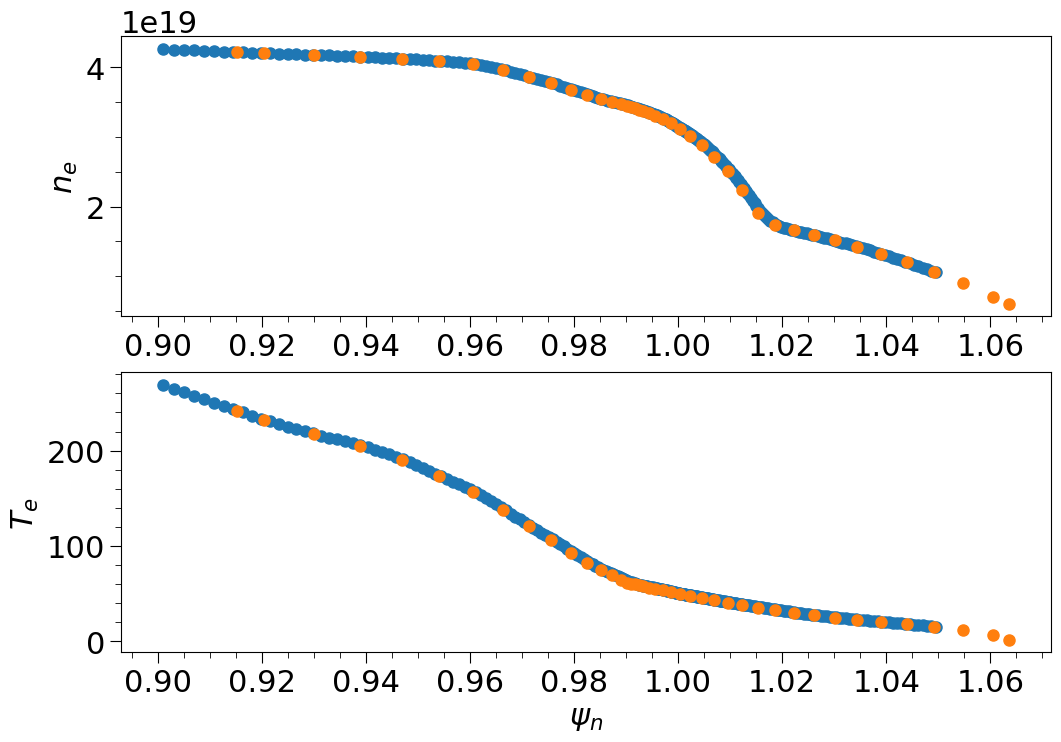

In [7]:
bout_psin = mapper.bout.psinxy[:,mapper.bout.jomp]
bout_ne = mapper.bout.ne[:,mapper.bout.jomp]
bout_Te = mapper.bout.Te[:,mapper.bout.jomp]

solps_psin = mapper.solps.psinxy[:,mapper.solps.jomp]
solps_ne = mapper.solps.ne[:,mapper.solps.jomp]
solps_Te = mapper.solps.Te[:,mapper.solps.jomp]

fig, axs = plt.subplots(2,1)
axs[0].scatter(bout_psin, bout_ne,label="BOUT++")
axs[0].scatter(solps_psin, solps_ne,label="SOLPS")
axs[0].set_ylabel(r"$n_e$")

axs[1].scatter(bout_psin, bout_Te,label="BOUT++")
axs[1].scatter(solps_psin, solps_Te,label="SOLPS")
axs[1].set_xlabel(r"$\psi_n$")
axs[1].set_ylabel(r"$T_e$")